In [1]:
import os
import pandas as pd
from pathlib import Path

import urllib.parse

CAMINHO_CSV_LOCAL = "../../data/processed/sim_sc_processado_analitico.csv"
NOME_ARQUIVO = "sim_sc_processado_analitico.csv"

GITLAB_HOST = "https://codigos.ufsc.br"
PROJETO = "pyanalytics/pyanalytics"
BRANCH = "Retrato_mortalidade_municipio"
CAMINHO_NO_REPO = "data/processed/sim_sc_processado_analitico.csv"

URL_CSV = (
    f"{GITLAB_HOST}/api/v4/projects/{urllib.parse.quote(PROJETO, safe='')}"
    f"/repository/files/{urllib.parse.quote(CAMINHO_NO_REPO, safe='')}/raw"
    f"?ref={urllib.parse.quote(BRANCH, safe='')}"
)

GITLAB_TOKEN = ""

try:

    from google.colab import userdata
    GITLAB_TOKEN = userdata.get("GITLAB_TOKEN") or ""
    if GITLAB_TOKEN:
        print("Token do GitLab carregado do Colab Secrets.")
except Exception:
    pass

if not GITLAB_TOKEN:
    import getpass
    GITLAB_TOKEN = getpass.getpass(
        "Token do GitLab (escopo read_repository). Deixe em branco e aperte "
        "Enter se o repositorio for publico: "
    ).strip()

def resolve_caminho_csv(caminho_local, url, nome_arquivo, token=""):
    """Retorna o caminho de um CSV local valido. Primeiro tenta `caminho_local`
    (e algumas pastas acima, subindo a arvore de diretorios); se nao encontrar,
    baixa o arquivo de `url` para o diretorio atual e retorna esse caminho."""
    p = Path(caminho_local)
    if p.exists():
        return str(p)

    atual = Path.cwd()
    for _ in range(6):
        candidato = atual / "data" / "processed" / nome_arquivo
        if candidato.exists():
            print(f"Aviso: CAMINHO_CSV configurado ('{caminho_local}') não encontrado a partir de "
                  f"'{Path.cwd()}'. Localizei o arquivo automaticamente em '{candidato}' e vou usá-lo.")
            return str(candidato)
        atual = atual.parent

    destino = Path(nome_arquivo)
    if destino.exists() and destino.stat().st_size > 0:
        print(f"Usando CSV já baixado anteriormente em: {destino.resolve()}")
        return str(destino)

    print(f"Arquivo não encontrado localmente. Baixando de:\n  {url}")
    if token:
        comando = f'wget -q --header="PRIVATE-TOKEN: {token}" -O "{destino}" "{url}"'
    else:
        comando = f'wget -q -O "{destino}" "{url}"'
    resultado = os.system(comando)

    def _e_html(caminho):
        """Detecta se o arquivo baixado e na verdade uma pagina de erro/login em
        HTML (sinal classico de token invalido/ausente em repositorio privado),
        em vez do CSV esperado."""
        try:
            with open(caminho, "r", encoding="utf-8", errors="ignore") as fh:
                inicio = fh.read(500).strip().lower()
            return inicio.startswith("<!doctype") or inicio.startswith("<html")
        except Exception:
            return False

    download_falhou = resultado != 0 or not destino.exists() or destino.stat().st_size == 0
    download_e_html = destino.exists() and destino.stat().st_size > 0 and _e_html(destino)

    if download_falhou or download_e_html:
        if destino.exists():
            destino.unlink()
        motivo_extra = (
            "\n  - O conteúdo baixado era uma página HTML (login/erro), não um CSV — "
            "sinal de que o token está ausente, incorreto, ou o repositório é privado."
            if download_e_html else ""
        )
        raise FileNotFoundError(
            f"Não foi possível obter o CSV do projeto.\n"
            f"  - Caminho local tentado: {caminho_local}\n"
            f"  - Diretório de trabalho atual (os.getcwd()): {Path.cwd()}\n"
            f"  - Também tentei baixar de: {url}"
            f"{motivo_extra}\n"
            f"Se o repositório do GitLab for privado, configure o GITLAB_TOKEN (via Colab Secrets "
            f"ou o prompt oculto acima) com um Personal Access Token válido (escopo read_repository) "
            f"e rode a célula novamente."
        )

    print(f"CSV baixado com sucesso em: {destino.resolve()}")
    return str(destino)

CAMINHO_CSV = resolve_caminho_csv(CAMINHO_CSV_LOCAL, URL_CSV, NOME_ARQUIVO, GITLAB_TOKEN)
print(f"Usando CSV em: {CAMINHO_CSV}")

CAMPOS = ["DTOBITO", "IDADE", "SEXO", "RACACOR", "ESC2010", "CODMUNRES", "CODMUNOCOR", "LOCOCOR", "CAUSABAS"]
COD_ARARANGUA = "420140"

ANO_INICIO, ANO_FIM = None, None


Token do GitLab (escopo read_repository). Deixe em branco e aperte Enter se o repositorio for publico: ··········
Arquivo não encontrado localmente. Baixando de:
  https://codigos.ufsc.br/api/v4/projects/pyanalytics%2Fpyanalytics/repository/files/data%2Fprocessed%2Fsim_sc_processado_analitico.csv/raw?ref=Retrato_mortalidade_municipio
CSV baixado com sucesso em: /content/sim_sc_processado_analitico.csv
Usando CSV em: sim_sc_processado_analitico.csv


In [2]:
def decodifica_idade(valor):
    """IDADE = 1 digito de unidade + 2 digitos de quantidade.
    1-minuto, 2-hora, 3-mes, 4-ano, 5-mais de 100 anos, 9-ignorado."""
    if pd.isna(valor) or valor in (None, ""):
        return None
    v = str(valor).zfill(3)
    unidade, qtd = v[0], v[1:]
    mapa_unidade = {
        "1": "minuto(s)",
        "2": "hora(s)",
        "3": "mes(es)",
        "4": "ano(s)",
        "5": "ano(s) (100+)",
        "9": "idade ignorada",
    }
    if unidade == "9":
        return "Ignorado"
    return f"{int(qtd)} {mapa_unidade.get(unidade, 'unidade desconhecida')}"

MAPA_SEXO = {"1": "Masculino", "2": "Feminino", "0": "Ignorado", "9": "Ignorado",
             "M": "Masculino", "F": "Feminino", "I": "Ignorado"}

MAPA_RACACOR = {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indigena"}

MAPA_ESC2010 = {
    "0": "Sem escolaridade",
    "1": "Fundamental I (1a a 4a serie)",
    "2": "Fundamental II (5a a 8a serie)",
    "3": "Medio (antigo 2o Grau)",
    "4": "Superior incompleto",
    "5": "Superior completo",
    "9": "Ignorado",
}

MAPA_LOCOCOR = {
    "1": "Hospital",
    "2": "Outros estabelecimentos de saude",
    "3": "Domicilio",
    "4": "Via publica",
    "5": "Outros",
    "6": "Aldeia indigena",
    "9": "Ignorado",
}

!wget -q -O CID-10-CATEGORIAS.CSV "https://raw.githubusercontent.com/cleytonferrari/CidDataSus/master/CIDImport/Repositorio/Resources/CID-10-CATEGORIAS.CSV"
cid10 = pd.read_csv("CID-10-CATEGORIAS.CSV", sep=";", encoding="latin1")
cid10["CAT"] = cid10["CAT"].astype(str).str.strip().str.upper()
MAPA_CID10 = dict(zip(cid10["CAT"], cid10["DESCRICAO"]))

def decodifica_causabas(codigo):
    """CAUSABAS normalmente vem com 4 caracteres (categoria + subcategoria,
    ex: 'A419'). A tabela CID-10-CATEGORIAS traz a descricao apenas no nivel
    de categoria (3 caracteres, ex: 'A41'), entao usamos os 3 primeiros
    caracteres do codigo para localizar a doenca."""
    if pd.isna(codigo) or str(codigo).strip() == "":
        return None
    cod = str(codigo).strip().upper()
    cat = cod[:3]
    return MAPA_CID10.get(cat, f"Desconhecido ({cod})")

!wget -q -O municipios_ibge.csv "https://raw.githubusercontent.com/kelvins/municipios-brasileiros/main/csv/municipios.csv"
municipios_ibge = pd.read_csv("municipios_ibge.csv")
municipios_ibge["COD6"] = municipios_ibge["codigo_ibge"].astype(str).str[:6]
MAPA_MUNICIPIO = dict(zip(municipios_ibge["COD6"], municipios_ibge["nome"]))

def decodifica_municipio(codigo):
    """Converte um codigo IBGE de 6 digitos (padrao SIM/DATASUS) no nome do
    municipio correspondente."""
    if pd.isna(codigo) or str(codigo).strip() == "":
        return None
    cod6 = str(codigo).strip().zfill(6)[:6]
    return MAPA_MUNICIPIO.get(cod6, f"Desconhecido ({cod6})")

# --- Ocupacao (CBO 2002), para o cruzamento "obitos por ocupacao" ---------
!wget -q -O CBO2002.csv "https://raw.githubusercontent.com/lucassmacedo/cbo-brasil/master/csv/CBO2002%20-%20Ocupacao.csv"
try:
    cbo = pd.read_csv("CBO2002.csv", sep=";", encoding="utf-8")
    cbo["code"] = cbo["code"].astype(str).str.zfill(6)
    MAPA_CBO = dict(zip(cbo["code"], cbo["name"]))
except Exception as e:
    print(f"Aviso: nao foi possivel carregar a tabela de ocupacoes (CBO): {e}")
    MAPA_CBO = {}

def decodifica_ocupacao(codigo):
    """Converte o codigo CBO (6 digitos, campo OCUP do SIM) na descricao da
    ocupacao. Codigos 999999/000000 (ou vazios) sao tratados como
    'Ignorado/Nao se aplica' (comuns em obitos de criancas e em registros
    antigos em que o campo nao era preenchido de forma padronizada)."""
    if pd.isna(codigo) or str(codigo).strip() in ("", "nan"):
        return None
    cod = str(codigo).strip().zfill(6)
    if cod in ("999999", "000000"):
        return "Ignorado/Não se aplica"
    return MAPA_CBO.get(cod, f"Desconhecido ({cod})")

# --- Populacao dos municipios, para normalizar obitos por habitante -------
!wget -q -O municipios_pop.csv "https://raw.githubusercontent.com/mapaslivres/municipios-br/main/tabelas/municipios.csv"
try:
    pop_df = pd.read_csv("municipios_pop.csv", dtype=str)
    pop_df["COD6"] = pop_df["municipio"].astype(str).str[:6]
    MAPA_POPULACAO = dict(zip(pop_df["COD6"], pd.to_numeric(pop_df["pop_21"], errors="coerce")))
except Exception as e:
    print(f"Aviso: nao foi possivel carregar a tabela de populacao dos municipios: {e}")
    MAPA_POPULACAO = {}

def populacao_municipio(cod6):
    """Retorna a populacao estimada (IBGE 2021) do municipio (codigo IBGE de
    6 digitos, padrao SIM/DATASUS). Usada para normalizar obitos por
    habitante entre municipios de tamanhos diferentes. E uma aproximacao:
    usamos um unico ano de populacao (2021) para todo o periodo analisado,
    ja que nao ha uma serie historica de populacao facilmente disponivel
    ano a ano para todos os municipios de SC."""
    return MAPA_POPULACAO.get(str(cod6).strip().zfill(6))


In [3]:
colunas_disponiveis = set(pd.read_csv(CAMINHO_CSV, nrows=0).columns)


CANDIDATOS_OCUPACAO = ["OCUP", "CODOCUP", "OCUPACAO", "COD_OCUPACAO"]
CANDIDATOS_RENDA = ["REMUNERACAO", "RENDA", "FAIXARENDA", "FAIXA_RENDA", "VALORSC", "REMUNSM", "RENDAMENSAL"]
COL_OCUPACAO = next((c for c in CANDIDATOS_OCUPACAO if c in colunas_disponiveis), None)
COL_RENDA = next((c for c in CANDIDATOS_RENDA if c in colunas_disponiveis), None)

CAMPOS_EXTRA = [c for c in (COL_OCUPACAO, COL_RENDA) if c]
CAMPOS_DISPONIVEIS = [c for c in CAMPOS + CAMPOS_EXTRA if c in colunas_disponiveis]
faltantes = set(CAMPOS) - set(CAMPOS_DISPONIVEIS)
if faltantes:
    print(f"Aviso: colunas nao encontradas no CSV e ignoradas: {faltantes}")
print(f"Coluna de ocupação detectada: {COL_OCUPACAO or 'nenhuma'}")
print(f"Coluna de remuneração/renda detectada: {COL_RENDA or 'nenhuma (campo não existe no SIM/DATASUS)'}")

blocos = []
total_lido = 0
for bloco in pd.read_csv(CAMINHO_CSV, sep=",", encoding="utf-8-sig", usecols=CAMPOS_DISPONIVEIS,
                          dtype=str, chunksize=200_000):
    total_lido += len(bloco)
    blocos.append(bloco[bloco["CODMUNRES"].astype(str).str[:6] == COD_ARARANGUA])
df_ararangua = pd.concat(blocos, ignore_index=True)
del blocos

df_ararangua["DTOBITO"] = pd.to_datetime(df_ararangua["DTOBITO"], errors="coerce").dt.strftime("%d/%m/%Y")
df_ararangua["IDADE"] = df_ararangua["IDADE"].apply(decodifica_idade)
df_ararangua["ESC2010"] = df_ararangua["ESC2010"].map(MAPA_ESC2010).fillna(df_ararangua["ESC2010"])
df_ararangua["CAUSABAS_DESC"] = df_ararangua["CAUSABAS"].apply(decodifica_causabas)
df_ararangua["SEXO"] = df_ararangua["SEXO"].map(MAPA_SEXO).fillna(df_ararangua["SEXO"])
df_ararangua["RACACOR"] = df_ararangua["RACACOR"].map(MAPA_RACACOR).fillna(df_ararangua["RACACOR"])
df_ararangua["LOCOCOR"] = df_ararangua["LOCOCOR"].map(MAPA_LOCOCOR).fillna(df_ararangua["LOCOCOR"])

if COL_OCUPACAO:
    df_ararangua["OCUPACAO_DESC"] = df_ararangua[COL_OCUPACAO].apply(decodifica_ocupacao)
if COL_RENDA:
    df_ararangua["RENDA_VALOR"] = df_ararangua[COL_RENDA]

# Municipio de residencia (nome) e municipio de ocorrencia do obito (codigo e nome)
df_ararangua["CODMUNRES_NOME"] = df_ararangua["CODMUNRES"].apply(decodifica_municipio)
if "CODMUNOCOR" in df_ararangua.columns:
    df_ararangua["CODMUNOCOR_NOME"] = df_ararangua["CODMUNOCOR"].apply(decodifica_municipio)
else:
    df_ararangua["CODMUNOCOR"] = df_ararangua["CODMUNRES"]
    df_ararangua["CODMUNOCOR_NOME"] = df_ararangua["CODMUNRES_NOME"]
    print("Aviso: CODMUNOCOR indisponivel no CSV; usando CODMUNRES como aproximacao.")

print(f"Total de registros verificados: {total_lido}")
print(f"Registros de Araranguá (todos os anos disponíveis): {len(df_ararangua)}")

ano_obito = pd.to_datetime(df_ararangua["DTOBITO"], format="%d/%m/%Y", errors="coerce").dt.year
if ANO_INICIO is not None or ANO_FIM is not None:
    ini = ANO_INICIO if ANO_INICIO is not None else int(ano_obito.min())
    fim = ANO_FIM if ANO_FIM is not None else int(ano_obito.max())
    df_ararangua = df_ararangua[ano_obito.between(ini, fim)].reset_index(drop=True)
    print(f"Registros de Araranguá em {ini}-{fim}: {len(df_ararangua)}")

ano_obito_final = pd.to_datetime(df_ararangua["DTOBITO"], format="%d/%m/%Y", errors="coerce").dt.year
ANO_MIN = int(ano_obito_final.min())
ANO_MAX = int(ano_obito_final.max())
PERIODO_TITULO = f"{ANO_MIN}-{ANO_MAX}" if ANO_MIN != ANO_MAX else f"{ANO_MIN}"

print(f"\nPeríodo efetivo dos dados carregados: {PERIODO_TITULO} ({len(df_ararangua)} óbitos)")
df_ararangua


Coluna de ocupação detectada: OCUP
Coluna de remuneração/renda detectada: nenhuma (campo não existe no SIM/DATASUS)
Total de registros verificados: 1502195
Registros de Araranguá (todos os anos disponíveis): 15608

Período efetivo dos dados carregados: 1992-2025 (15608 óbitos)


,DTOBITO,IDADE,SEXO,RACACOR,ESC2010,OCUP,CODMUNRES,LOCOCOR,CODMUNOCOR,CAUSABAS,CAUSABAS_DESC,OCUPACAO_DESC,CODMUNRES_NOME,CODMUNOCOR_NOME
0,30/08/2000,45 ano(s),Masculino,Branca,NaN,98500,4201406,Via publica,3505401,V892,Acidente com um veículo a motor ou não-motoriz...,Desconhecido (098500),Araranguá,Barra do Turvo
1,18/08/2000,35 ano(s),Masculino,Branca,NaN,98500,4201406,Hospital,3513504,V892,Acidente com um veículo a motor ou não-motoriz...,Desconhecido (098500),Araranguá,Cubatão
2,02/01/2000,79 ano(s),Masculino,NaN,NaN,00700,4201406,Hospital,4204608,I64,"Acidente vascular cerebral, não especificado c...",Desconhecido (000700),Araranguá,Criciúma
3,01/01/2000,17 ano(s),Feminino,Branca,NaN,00200,4201406,Hospital,4204608,O249,Diabetes mellitus na gravidez,Desconhecido (000200),Araranguá,Criciúma
4,21/02/2000,60 ano(s),Masculino,Branca,NaN,98500,4201406,Via publica,4211108,V645,Ocupante de um veículo de transporte pesado tr...,Desconhecido (098500),Araranguá,Monte Castelo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15603,14/07/1999,33 ano(s),Feminino,Branca,NaN,00800,4201406,Hospital,4314902,K088,Outros transtornos dos dentes e de suas estrut...,Desconhecido (000800),Araranguá,Porto Alegre
15604,21/06/1999,61 ano(s),Feminino,Branca,NaN,00700,4201406,NaN,4314902,A419,Outras septicemias,Desconhecido (000700),Araranguá,Porto Alegre
15605,24/09/1999,13 ano(s),Feminino,Branca,NaN,00600,4201406,Hospital,4314902,C719,Neoplasia maligna do encéfalo,Desconhecido (000600),Araranguá,Porto Alegre
15606,08/12/1999,62 ano(s),Masculino,Branca,NaN,00700,4201406,Hospital,4314902,E142,Diabetes mellitus não especificado,Desconhecido (000700),Araranguá,Porto Alegre


In [4]:
df = df_ararangua

df["DTOBITO_DT"] = pd.to_datetime(df["DTOBITO"], format="%d/%m/%Y")
df["ANOMES"] = df["DTOBITO_DT"].dt.to_period("M").astype(str)
df["ANO_OBITO"] = df["DTOBITO_DT"].dt.year

def idade_em_anos(valor):
    """Converte '60 ano(s)' -> 60. Para meses/horas/minutos, considera menor
    que 1 ano (retorna 0)."""
    if "ano(s)" in str(valor):
        try:
            return int(str(valor).split(" ")[0])
        except ValueError:
            return None
    return 0

df["IDADE_ANOS"] = df["IDADE"].apply(idade_em_anos)

faixas = [0, 1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 200]
rotulos_faixas = ["<1", "1-9", "10-19", "20-29", "30-39", "40-49",
                   "50-59", "60-69", "70-79", "80-89", "90+"]
df["FAIXA_ETARIA"] = pd.cut(df["IDADE_ANOS"], bins=faixas, labels=rotulos_faixas, right=False)

df["OCORREU_FORA_RESIDENCIA"] = (
    df["CODMUNOCOR"].astype(str).str.zfill(6) != df["CODMUNRES"].astype(str).str.zfill(6)
)

# Rotulos curtos para os graficos (a descricao completa fica na legenda)

MAPA_ESC_CURTO = {
    "Sem escolaridade": "Sem esc.",
    "Fundamental I (1a a 4a serie)": "Fund. I",
    "Fundamental II (5a a 8a serie)": "Fund. II",
    "Medio (antigo 2o Grau)": "Médio",
    "Superior incompleto": "Sup. incompleto",
    "Superior completo": "Sup. completo",
    "Ignorado": "Ignorado",
}

MAPA_LOCAL_CURTO = {
    "Hospital": "Hospital",
    "Outros estabelecimentos de saude": "OES",
    "Domicilio": "Domicílio",
    "Via publica": "Via pública",
    "Outros": "Outros",
    "Aldeia indigena": "Aldeia indíg.",
    "Ignorado": "Ignorado",
}

def abrevia_causa(texto, tamanho=35):
    """Abrevia o nome da causa para caber no eixo do grafico, adicionando
    reticencias. A descricao completa e mostrada separadamente em legenda."""
    if texto is None:
        return texto
    texto = str(texto)
    return texto if len(texto) <= tamanho else texto[:tamanho - 1].rstrip() + "…"


Total de óbitos no período 1992-2025: 15608


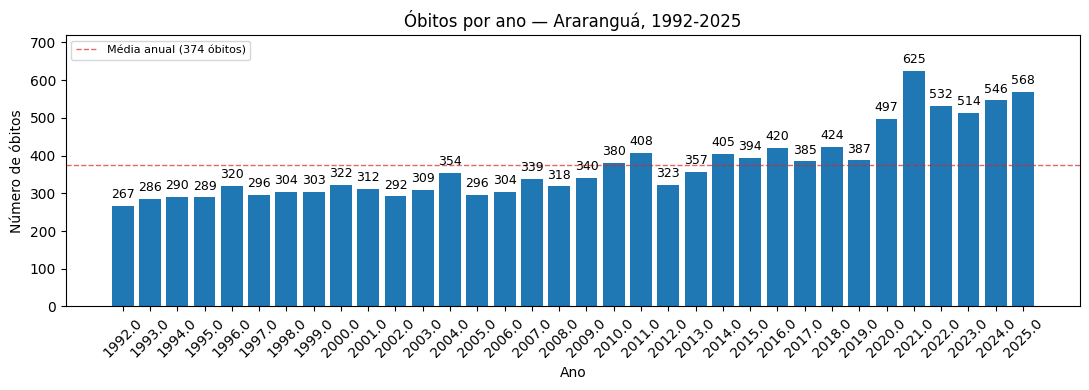

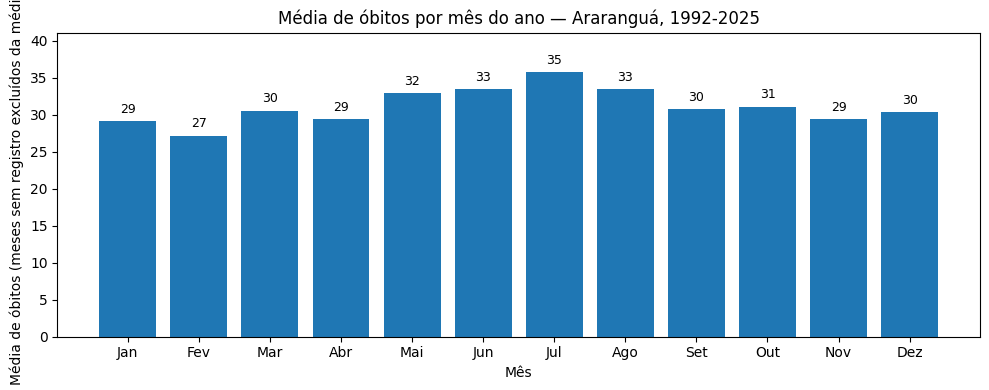

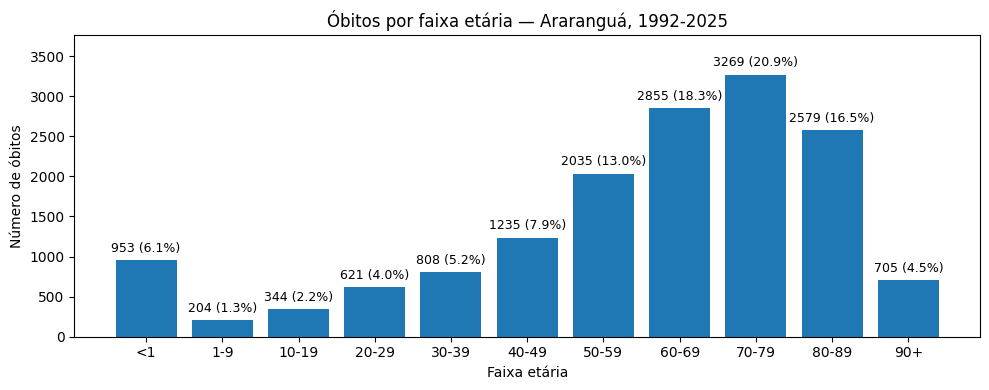

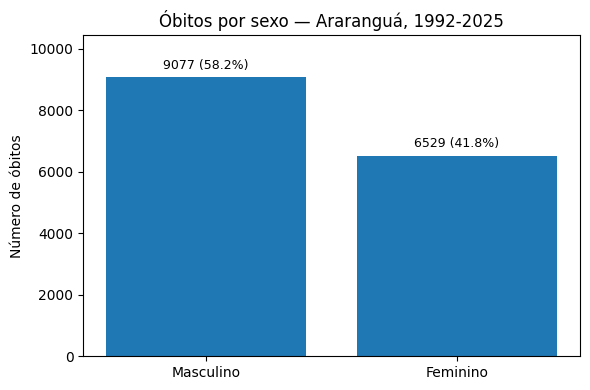

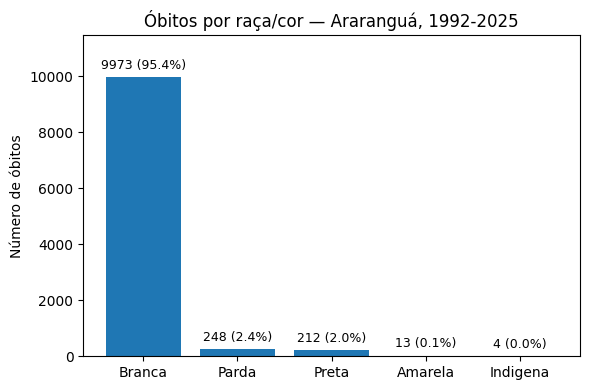

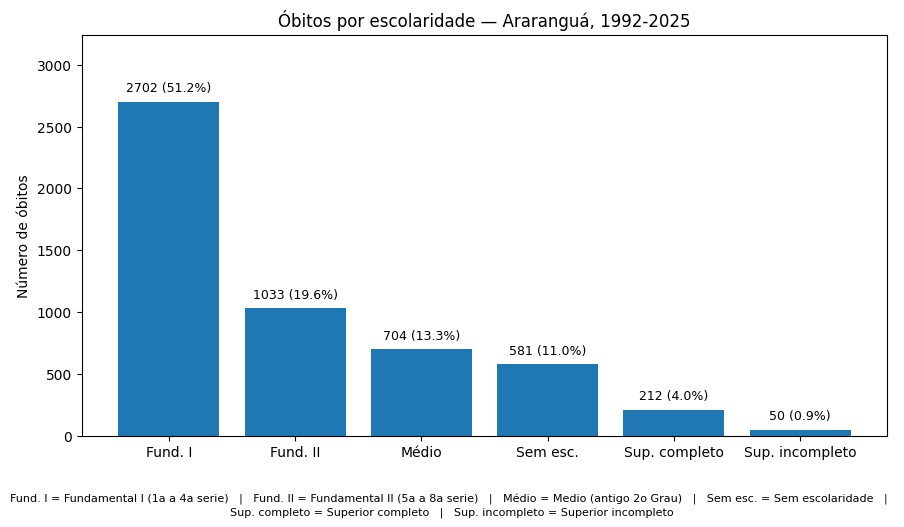

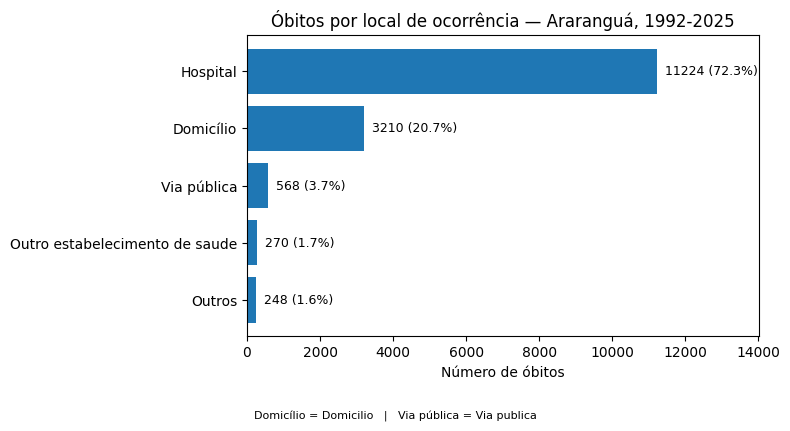

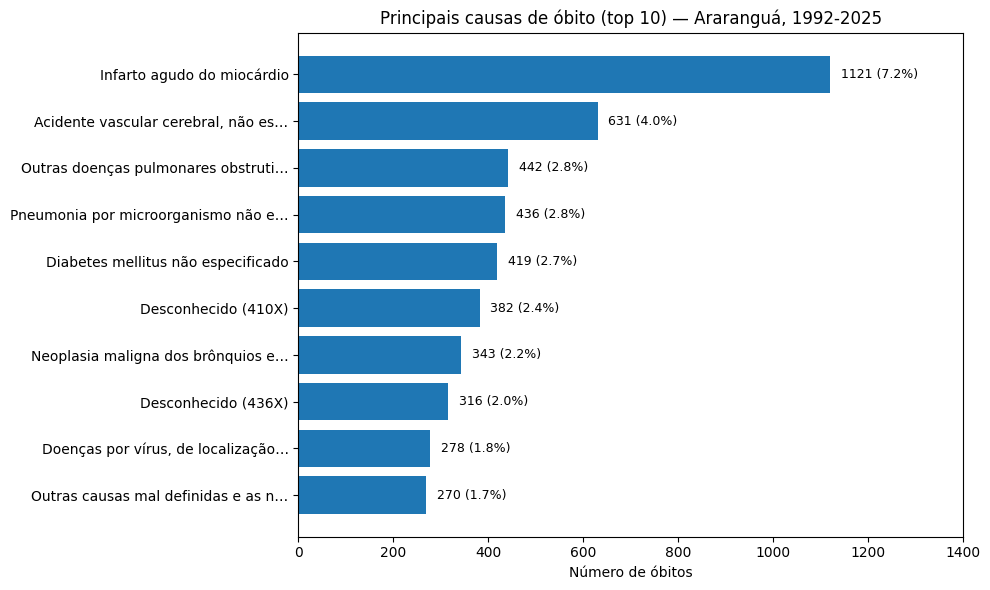

Legenda — descrição completa das causas abreviadas no gráfico acima:
  Infarto agudo do miocárdio  =  Infarto agudo do miocárdio
  Acidente vascular cerebral, não es…  →  Acidente vascular cerebral, não especificado como hemorrágico ou isquêmico
  Outras doenças pulmonares obstruti…  →  Outras doenças pulmonares obstrutivas crônicas
  Pneumonia por microorganismo não e…  →  Pneumonia por microorganismo não especificada
  Diabetes mellitus não especificado  =  Diabetes mellitus não especificado
  Desconhecido (410X)  =  Desconhecido (410X)
  Neoplasia maligna dos brônquios e…  →  Neoplasia maligna dos brônquios e dos pulmões
  Desconhecido (436X)  =  Desconhecido (436X)
  Doenças por vírus, de localização…  →  Doenças por vírus, de localização não especificada
  Outras causas mal definidas e as n…  →  Outras causas mal definidas e as não especificadas de mortalidade


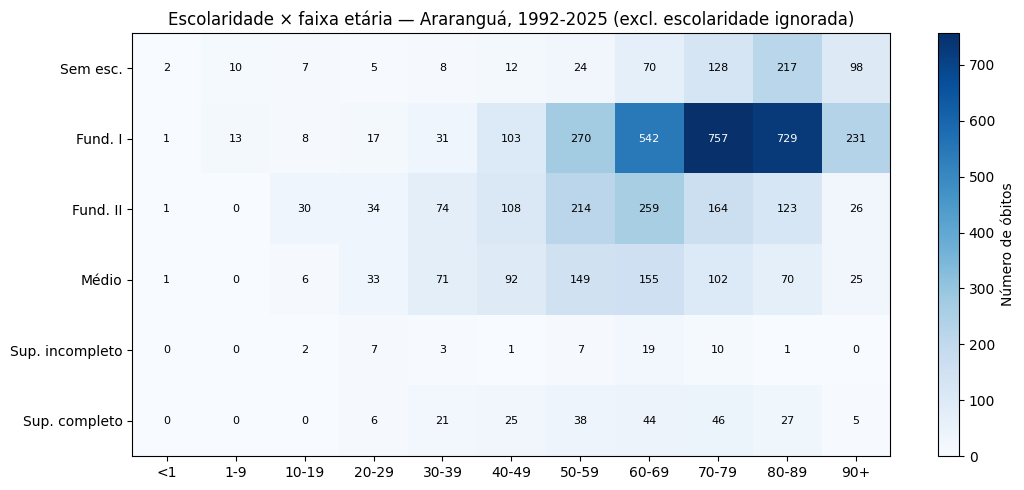

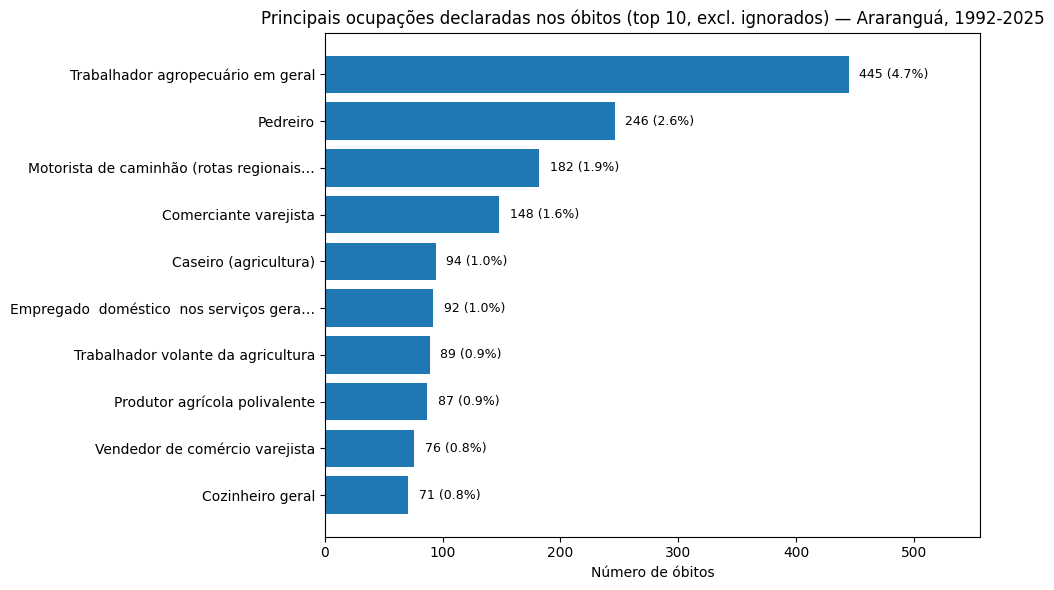

Óbitos por remuneração: a Declaração de Óbito (SIM/DATASUS) não coleta renda ou remuneração da pessoa falecida — esse campo não existe na base processada, então este gráfico não pôde ser gerado. Como aproximação indireta de condição socioeconômica, use os gráficos de Escolaridade e (quando disponível) Ocupação acima, já que renda individual não é registrada no SIM.


In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

def imprime_insight(texto):
    """Imprime um pequeno comentário logo abaixo do gráfico, com uma leitura
    rápida do que os dados mostram. Não substitui uma análise mais
    aprofundada, mas ajuda a orientar a interpretação de cada imagem."""
    print(f"Insight: {texto}\n")

def rotula_barras_vertical(ax, valores, total, mostrar_pct=True):
    """Adiciona 'n' (e opcionalmente '(pct%)') acima de cada barra vertical.
    mostrar_pct=False é usado quando há muitas barras (ex.: série de anos),
    pois nesses casos os rótulos de percentual se acumulam/sobrepõem uns nos
    outros e atrapalham a leitura do gráfico."""
    offset = max(valores) * 0.02 if len(valores) else 0
    for i, v in enumerate(valores):
        if pd.isna(v):
            continue
        if mostrar_pct:
            pct = 100 * v / total if total else 0
            texto = f"{int(v)} ({pct:.1f}%)"
        else:
            texto = f"{int(v)}"
        ax.text(i, v + offset, texto, ha="center", va="bottom", fontsize=9)

def rotula_barras_horizontal(ax, valores, total):
    """Adiciona 'n (pct%)' ao final de cada barra horizontal."""
    offset = max(valores) * 0.02 if len(valores) else 0
    for i, v in enumerate(valores):
        if pd.isna(v):
            continue
        pct = 100 * v / total if total else 0
        ax.text(v + offset, i, f"{int(v)} ({pct:.1f}%)", ha="left", va="center", fontsize=9)


obitos_por_ano = df["ANO_OBITO"].value_counts().sort_index()
total_ano = obitos_por_ano.sum()
print(f"Total de óbitos no período {PERIODO_TITULO}: {len(df)}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(obitos_por_ano.index.astype(str), obitos_por_ano.values)

rotula_barras_vertical(ax, obitos_por_ano.values, total_ano, mostrar_pct=False)
media_anual = obitos_por_ano.mean()
ax.axhline(media_anual, color="tab:red", linestyle="--", linewidth=1, alpha=0.7,
           label=f"Média anual ({media_anual:.0f} óbitos)")
ax.legend(fontsize=8)
ax.set_title(f"Óbitos por ano — Araranguá, {PERIODO_TITULO}")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de óbitos")
ax.margins(y=0.15)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


df["MES_OBITO"] = df["DTOBITO_DT"].dt.month
contagem_ano_mes = df.groupby(["ANO_OBITO", "MES_OBITO"]).size().unstack("MES_OBITO")
media_mensal = contagem_ano_mes.mean(axis=0, skipna=True).reindex(range(1, 13))

NOMES_MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
media_mensal.index = NOMES_MESES

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(media_mensal.index, media_mensal.values, color="tab:blue")
rotula_barras_vertical(ax, media_mensal.values, media_mensal.values.sum(), mostrar_pct=False)
ax.set_title(f"Média de óbitos por mês do ano — Araranguá, {PERIODO_TITULO}")
ax.set_xlabel("Mês")
ax.set_ylabel("Média de óbitos (meses sem registro excluídos da média)")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

obitos_por_faixa = df["FAIXA_ETARIA"].value_counts().reindex(rotulos_faixas).fillna(0)
total_faixa = obitos_por_faixa.sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(obitos_por_faixa.index.astype(str), obitos_por_faixa.values)
rotula_barras_vertical(ax, obitos_por_faixa.values, total_faixa)
ax.set_title(f"Óbitos por faixa etária — Araranguá, {PERIODO_TITULO}")
ax.set_xlabel("Faixa etária")
ax.set_ylabel("Número de óbitos")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


obitos_por_sexo = df.loc[df["SEXO"] != "Ignorado", "SEXO"].value_counts()
total_sexo = obitos_por_sexo.sum()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(obitos_por_sexo.index, obitos_por_sexo.values)
rotula_barras_vertical(ax, obitos_por_sexo.values, total_sexo)
ax.set_title(f"Óbitos por sexo — Araranguá, {PERIODO_TITULO}")
ax.set_ylabel("Número de óbitos")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


obitos_por_raca = df.loc[~df["RACACOR"].isin(["Ignorado", "9"]), "RACACOR"].value_counts()
total_raca = obitos_por_raca.sum()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(obitos_por_raca.index, obitos_por_raca.values)
rotula_barras_vertical(ax, obitos_por_raca.values, total_raca)
ax.set_title(f"Óbitos por raça/cor — Araranguá, {PERIODO_TITULO}")
ax.set_ylabel("Número de óbitos")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


obitos_por_esc = df.loc[df["ESC2010"] != "Ignorado", "ESC2010"].value_counts()
total_esc = obitos_por_esc.sum()
labels_curtos_esc = [MAPA_ESC_CURTO.get(cat, cat) for cat in obitos_por_esc.index]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(labels_curtos_esc, obitos_por_esc.values)
rotula_barras_vertical(ax, obitos_por_esc.values, total_esc)
ax.set_title(f"Óbitos por escolaridade — Araranguá, {PERIODO_TITULO}")
ax.set_ylabel("Número de óbitos")
ax.margins(y=0.2)
legenda_esc = "   |   ".join(f"{curto} = {completo}" for curto, completo in zip(labels_curtos_esc, obitos_por_esc.index))
plt.figtext(0.5, -0.08, legenda_esc, wrap=True, ha="center", fontsize=8)
plt.tight_layout()
plt.show()


obitos_por_local = df.loc[df["LOCOCOR"] != "Ignorado", "LOCOCOR"].value_counts()
total_local = obitos_por_local.sum()
labels_curtos_local = [MAPA_LOCAL_CURTO.get(cat, cat) for cat in obitos_por_local.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(labels_curtos_local, obitos_por_local.values)
rotula_barras_horizontal(ax, obitos_por_local.values, total_local)
ax.set_title(f"Óbitos por local de ocorrência — Araranguá, {PERIODO_TITULO}")
ax.set_xlabel("Número de óbitos")
ax.invert_yaxis()
ax.margins(x=0.25)
legenda_local = "   |   ".join(
    f"{curto} = {completo}" for curto, completo in zip(labels_curtos_local, obitos_por_local.index) if curto != completo
)
if legenda_local:
    plt.figtext(0.5, -0.06, legenda_local, wrap=True, ha="center", fontsize=8)
plt.tight_layout()
plt.show()


top_causas = df["CAUSABAS_DESC"].value_counts().head(10)
total_causas = df["CAUSABAS_DESC"].value_counts().sum()
labels_abrev_causa = [abrevia_causa(c) for c in top_causas.index]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels_abrev_causa, top_causas.values)
rotula_barras_horizontal(ax, top_causas.values, total_causas)
ax.set_title(f"Principais causas de óbito (top 10) — Araranguá, {PERIODO_TITULO}")
ax.set_xlabel("Número de óbitos")
ax.invert_yaxis()
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

print("Legenda — descrição completa das causas abreviadas no gráfico acima:")
for abrev, completo in zip(labels_abrev_causa, top_causas.index):
    marca = "→" if abrev != completo else "="
    print(f"  {abrev}  {marca}  {completo}")

# Escolaridade x faixa etaria (heatmap) — mostra se os obitos com menor
# escolaridade se concentram nas faixas etarias mais avancadas (efeito de
# coorte: geracoes mais antigas tiveram menos acesso a escola no passado).
df_esc_valida = df[df["ESC2010"] != "Ignorado"]
tabela_esc_faixa = pd.crosstab(
    df_esc_valida["ESC2010"], df_esc_valida["FAIXA_ETARIA"]
).reindex(columns=rotulos_faixas, fill_value=0)
ordem_esc = ["Sem escolaridade", "Fundamental I (1a a 4a serie)", "Fundamental II (5a a 8a serie)",
             "Medio (antigo 2o Grau)", "Superior incompleto", "Superior completo"]
tabela_esc_faixa = tabela_esc_faixa.reindex([o for o in ordem_esc if o in tabela_esc_faixa.index])

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(tabela_esc_faixa.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(tabela_esc_faixa.columns)))
ax.set_xticklabels(tabela_esc_faixa.columns)
ax.set_yticks(range(len(tabela_esc_faixa.index)))
ax.set_yticklabels([MAPA_ESC_CURTO.get(c, c) for c in tabela_esc_faixa.index])

valor_max_esc = tabela_esc_faixa.values.max() if tabela_esc_faixa.values.size else 0
for i in range(tabela_esc_faixa.shape[0]):
    for j in range(tabela_esc_faixa.shape[1]):
        val = tabela_esc_faixa.values[i, j]
        cor_texto = "white" if valor_max_esc and val > valor_max_esc / 2 else "black"
        ax.text(j, i, int(val), ha="center", va="center", color=cor_texto, fontsize=8)

ax.set_title(f"Escolaridade × faixa etária — Araranguá, {PERIODO_TITULO} (excl. escolaridade ignorada)")
plt.colorbar(im, ax=ax, label="Número de óbitos")
plt.tight_layout()
plt.show()


if COL_OCUPACAO:
    obitos_por_ocup = df["OCUPACAO_DESC"].value_counts()
    total_ocup = obitos_por_ocup.sum()
    rotulos_ignorar = {"Ignorado/Não se aplica"}
    obitos_por_ocup_validos = obitos_por_ocup[
        ~obitos_por_ocup.index.isin(rotulos_ignorar)
        & ~obitos_por_ocup.index.astype(str).str.startswith("Desconhecido")
    ]
    top10_ocup = obitos_por_ocup_validos.head(10)
    labels_ocup = [abrevia_causa(c, 40) for c in top10_ocup.index]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(labels_ocup, top10_ocup.values)
    rotula_barras_horizontal(ax, top10_ocup.values, total_ocup)
    ax.set_title(f"Principais ocupações declaradas nos óbitos (top 10, excl. ignorados) — "
                 f"Araranguá, {PERIODO_TITULO}")
    ax.set_xlabel("Número de óbitos")
    ax.invert_yaxis()
    ax.margins(x=0.25)
    plt.tight_layout()
    plt.show()

else:
    print("Óbitos por ocupação: nenhuma coluna de ocupação (OCUP/CODOCUP) foi encontrada no "
          "CSV processado — este gráfico não pôde ser gerado com a base disponível.")


if COL_RENDA:
    obitos_por_renda = df["RENDA_VALOR"].value_counts().sort_index()
    total_renda = obitos_por_renda.sum()

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(obitos_por_renda.index.astype(str), obitos_por_renda.values)
    rotula_barras_vertical(ax, obitos_por_renda.values, total_renda)
    ax.set_title(f"Óbitos por faixa de remuneração — Araranguá, {PERIODO_TITULO}")
    ax.set_xlabel("Faixa de remuneração")
    ax.set_ylabel("Número de óbitos")
    ax.margins(y=0.15)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Óbitos por remuneração: a Declaração de Óbito (SIM/DATASUS) não coleta renda ou "
        "remuneração da pessoa falecida — esse campo não existe na base processada, então "
        "este gráfico não pôde ser gerado. Como aproximação indireta de condição "
        "socioeconômica, use os gráficos de Escolaridade e (quando disponível) Ocupação "
        "acima, já que renda individual não é registrada no SIM."
    )


Óbitos por sexo e local de ocorrência (contagem absoluta):


LOCOCOR,Domicilio,Hospital,Outro estabelecimento de saude,Outros,Via publica
SEXO,,,,,
Feminino,1401,4886,54,52,102
Masculino,1809,6336,216,196,466



Distribuição percentual do local de ocorrência dentro de cada sexo:


LOCOCOR,Domicilio,Hospital,Outro estabelecimento de saude,Outros,Via publica
SEXO,,,,,
Feminino,21.6,75.2,0.8,0.8,1.6
Masculino,20.0,70.2,2.4,2.2,5.2


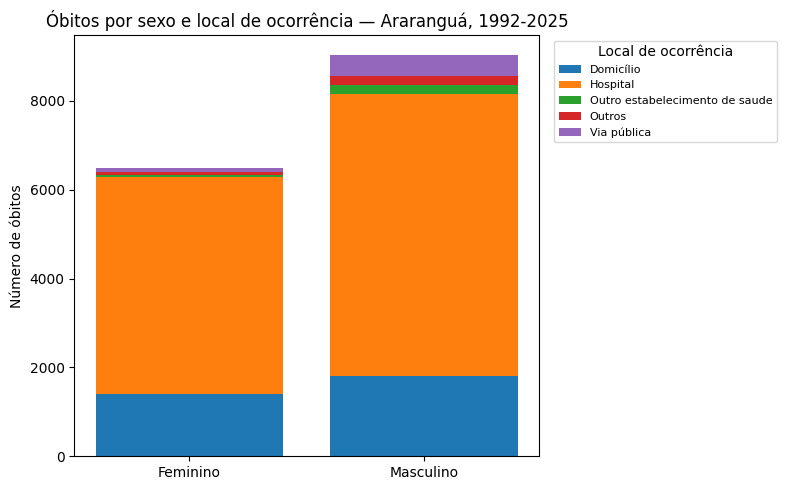

In [6]:

df_sexo_local = df[(df["SEXO"] != "Ignorado") & (df["LOCOCOR"] != "Ignorado")]
tabela_sexo_local = pd.crosstab(df_sexo_local["SEXO"], df_sexo_local["LOCOCOR"])
tabela_sexo_local_pct = pd.crosstab(df_sexo_local["SEXO"], df_sexo_local["LOCOCOR"], normalize="index") * 100

print("Óbitos por sexo e local de ocorrência (contagem absoluta):")
display(tabela_sexo_local)

print("\nDistribuição percentual do local de ocorrência dentro de cada sexo:")
display(tabela_sexo_local_pct.round(1))


fig, ax = plt.subplots(figsize=(8, 5))
bottom = pd.Series(0, index=tabela_sexo_local.index, dtype=float)
for col in tabela_sexo_local.columns:
    label_curto = MAPA_LOCAL_CURTO.get(col, col)
    valores = tabela_sexo_local[col]
    ax.bar(tabela_sexo_local.index, valores, bottom=bottom, label=label_curto)
    bottom += valores

ax.set_title(f"Óbitos por sexo e local de ocorrência — Araranguá, {PERIODO_TITULO}")
ax.set_ylabel("Número de óbitos")
ax.legend(title="Local de ocorrência", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


Número de óbitos por causa (top 5) e faixa etária:


FAIXA_ETARIA,<1,1-9,10-19,20-29,30-39,40-49,50-59,60-69,70-79,80-89,90+
CAUSABAS_DESC,,,,,,,,,,,
Infarto agudo do miocárdio,3,3,0,10,21,74,186,265,302,205,52
"Acidente vascular cerebral, não especificado como hemorrágico ou isquêmico",1,1,0,2,3,30,49,123,175,186,61
Outras doenças pulmonares obstrutivas crônicas,0,1,0,1,1,7,35,101,150,125,21
Pneumonia por microorganismo não especificada,9,10,6,4,10,15,25,49,103,139,66
Diabetes mellitus não especificado,0,0,1,4,4,16,62,111,123,74,24


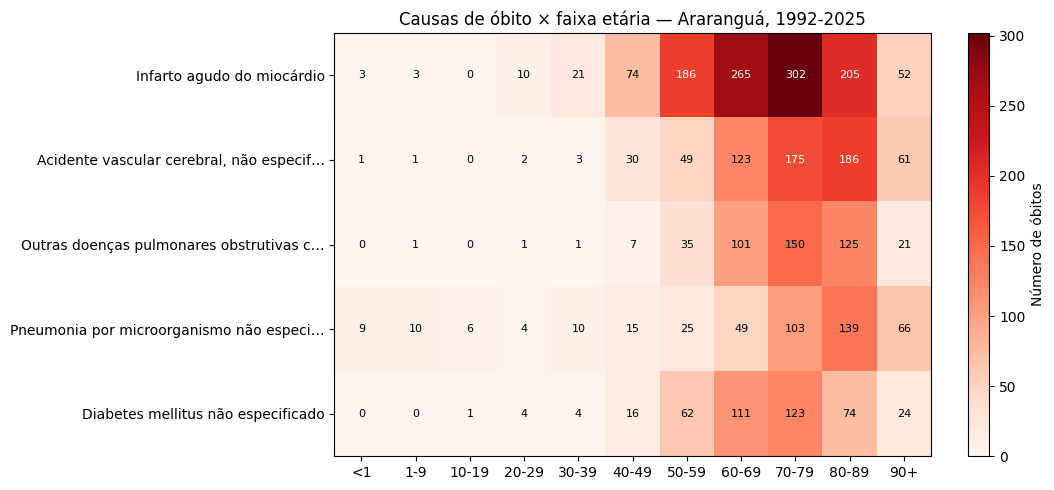


Principal causa de óbito em cada faixa etária:
  <1: Desconhecido (485X) (60 óbito(s))
  1-9: Pneumonia por microorganismo não especificada (10 óbito(s))
  10-19: Desconhecido (8199) (38 óbito(s))
  20-29: Desconhecido (8199) (53 óbito(s))
  30-39: Desconhecido (8199) (47 óbito(s))
  40-49: Infarto agudo do miocárdio (74 óbito(s))
  50-59: Infarto agudo do miocárdio (186 óbito(s))
  60-69: Infarto agudo do miocárdio (265 óbito(s))
  70-79: Infarto agudo do miocárdio (302 óbito(s))
  80-89: Infarto agudo do miocárdio (205 óbito(s))
  90+: Pneumonia por microorganismo não especificada (66 óbito(s))


In [7]:

top5_causas_geral = df["CAUSABAS_DESC"].value_counts().head(5).index.tolist()

df_top5_causas = df[df["CAUSABAS_DESC"].isin(top5_causas_geral)]
tabela_causa_faixa = pd.crosstab(
    df_top5_causas["CAUSABAS_DESC"], df_top5_causas["FAIXA_ETARIA"]
).reindex(index=top5_causas_geral, columns=rotulos_faixas, fill_value=0)

print("Número de óbitos por causa (top 5) e faixa etária:")
display(tabela_causa_faixa)

# Heatmap
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(tabela_causa_faixa.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(len(tabela_causa_faixa.columns)))
ax.set_xticklabels(tabela_causa_faixa.columns)
ax.set_yticks(range(len(tabela_causa_faixa.index)))
ax.set_yticklabels([abrevia_causa(c, 40) for c in tabela_causa_faixa.index])

valor_max = tabela_causa_faixa.values.max() if tabela_causa_faixa.values.size else 0
for i in range(tabela_causa_faixa.shape[0]):
    for j in range(tabela_causa_faixa.shape[1]):
        val = tabela_causa_faixa.values[i, j]
        cor_texto = "white" if valor_max and val > valor_max / 2 else "black"
        ax.text(j, i, int(val), ha="center", va="center", color=cor_texto, fontsize=8)

ax.set_title(f"Causas de óbito × faixa etária — Araranguá, {PERIODO_TITULO}")
plt.colorbar(im, ax=ax, label="Número de óbitos")
plt.tight_layout()
plt.show()

# Causa mais frequente em cada faixa etaria (olhando todas as causas, nao so o top 5)
print("\nPrincipal causa de óbito em cada faixa etária:")
for faixa in rotulos_faixas:
    subset = df.loc[df["FAIXA_ETARIA"] == faixa, "CAUSABAS_DESC"].value_counts()
    if len(subset) > 0:
        print(f"  {faixa}: {subset.index[0]} ({subset.iloc[0]} óbito(s))")
    else:
        print(f"  {faixa}: sem registros")


Araranguá está na posição 18ª de 1609 municípios de SC em número de óbitos registrados (1992-2025).


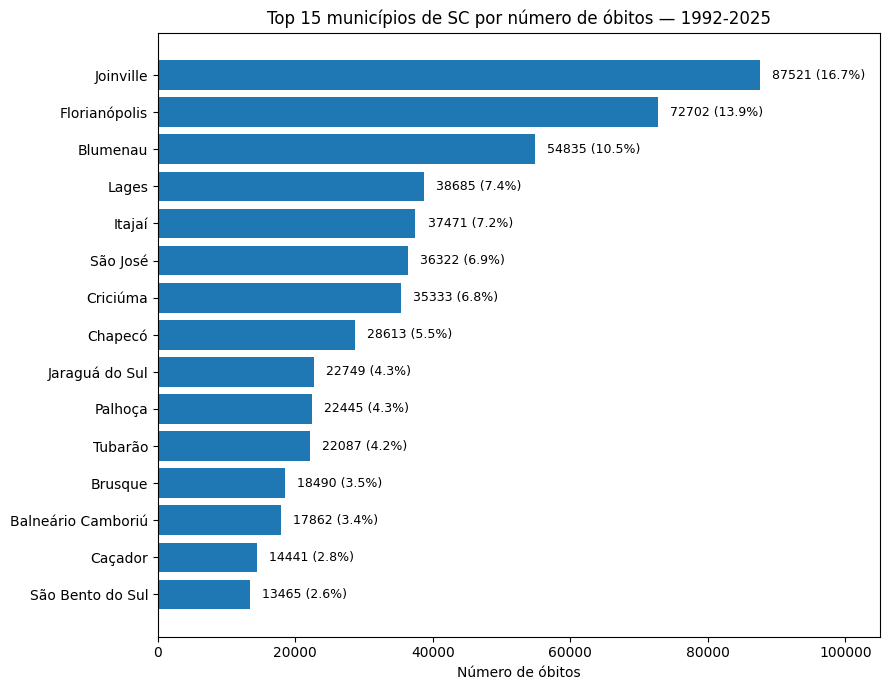


Aviso: 15 município(s) sem população encontrada na tabela de referência foram excluídos do ranking normalizado.

Taxa média anual de óbitos por 10.000 habitantes (normalizado pela população, IBGE 2021):


,óbitos/10 mil hab./ano
Imaruí,106.27
Galvão,100.57
Caxambu do Sul,97.36
São Bonifácio,96.00
Anita Garibaldi,93.88
Angelina,93.65
Marema,92.74
São Martinho,87.90
Campo Erê,86.90
Piratuba,85.80


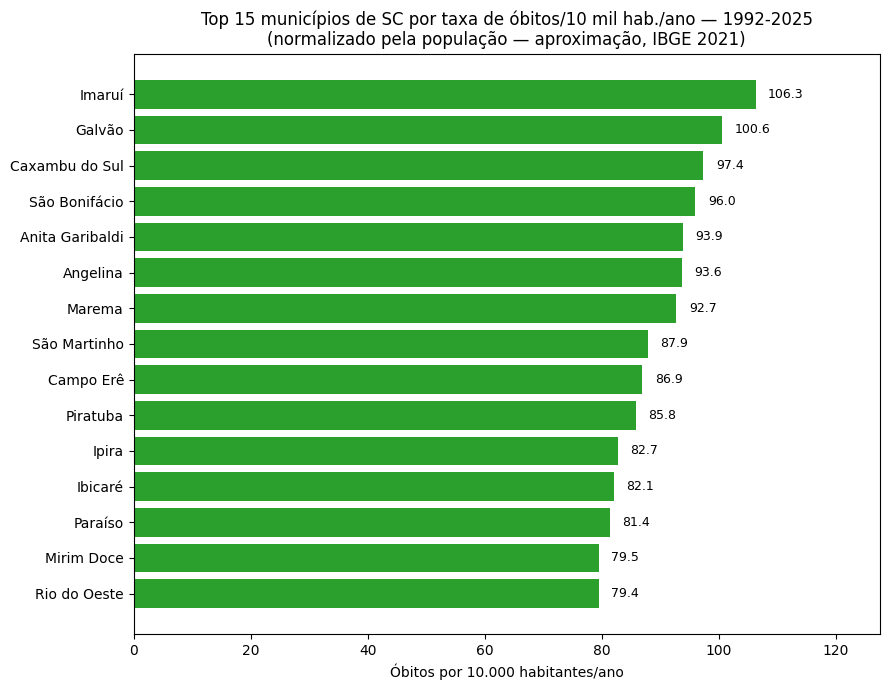

In [8]:

CAMPOS_RANKING = ["DTOBITO", "CODMUNRES"]
colunas_disp_rank = set(pd.read_csv(CAMINHO_CSV, nrows=0).columns)
CAMPOS_RANKING_DISP = [c for c in CAMPOS_RANKING if c in colunas_disp_rank]

contagem_municipios = {}
for bloco in pd.read_csv(CAMINHO_CSV, sep=",", encoding="utf-8-sig", usecols=CAMPOS_RANKING_DISP,
                          dtype=str, chunksize=200_000):
    ano_bloco = pd.to_datetime(bloco["DTOBITO"], errors="coerce").dt.year
    bloco_periodo = bloco[ano_bloco.between(ANO_MIN, ANO_MAX)]
    contagens = bloco_periodo["CODMUNRES"].astype(str).str[:6].value_counts()
    for cod, qtd in contagens.items():
        contagem_municipios[cod] = contagem_municipios.get(cod, 0) + qtd

ranking_codigos = pd.Series(contagem_municipios).sort_values(ascending=False)
ranking = ranking_codigos.copy()
ranking.index = [decodifica_municipio(c) for c in ranking.index]

nome_araranguá = decodifica_municipio(COD_ARARANGUA)
if nome_araranguá in ranking.index:
    posicao_araranguá = list(ranking.index).index(nome_araranguá) + 1
    print(f"Araranguá está na posição {posicao_araranguá}ª de {len(ranking)} municípios de SC "
          f"em número de óbitos registrados ({PERIODO_TITULO}).")
else:
    posicao_araranguá = None
    print("Araranguá não foi localizada no ranking (verifique o código do município).")

ranking_top15 = ranking.head(15)
fig, ax = plt.subplots(figsize=(9, 7))
cores = ["tab:red" if m == nome_araranguá else "tab:blue" for m in ranking_top15.index]
ax.barh(ranking_top15.index, ranking_top15.values, color=cores)
rotula_barras_horizontal(ax, ranking_top15.values, ranking_top15.values.sum())
ax.set_title(f"Top 15 municípios de SC por número de óbitos — {PERIODO_TITULO}")
ax.set_xlabel("Número de óbitos")
ax.invert_yaxis()
ax.margins(x=0.2)
plt.tight_layout()
plt.show()


anos_periodo = ANO_MAX - ANO_MIN + 1
taxa_por_10mil = {}
municipios_sem_populacao = 0
for cod, obitos in contagem_municipios.items():
    pop = MAPA_POPULACAO.get(str(cod).zfill(6))
    if pop and pop > 0:
        taxa_por_10mil[cod] = (obitos / anos_periodo) / pop * 10000
    else:
        municipios_sem_populacao += 1

taxa_serie_codigos = pd.Series(taxa_por_10mil).sort_values(ascending=False)
taxa_serie = taxa_serie_codigos.copy()
taxa_serie.index = [decodifica_municipio(c) for c in taxa_serie_codigos.index]

if municipios_sem_populacao:
    print(f"\nAviso: {municipios_sem_populacao} município(s) sem população encontrada na "
          f"tabela de referência foram excluídos do ranking normalizado.")

print("\nTaxa média anual de óbitos por 10.000 habitantes (normalizado pela população, IBGE 2021):")
taxa_top15 = taxa_serie.head(15)
display(taxa_top15.round(2).to_frame("óbitos/10 mil hab./ano"))

fig, ax = plt.subplots(figsize=(9, 7))
cores_taxa = ["tab:red" if m == nome_araranguá else "tab:green" for m in taxa_top15.index]
ax.barh(taxa_top15.index, taxa_top15.values, color=cores_taxa)
offset_taxa = taxa_top15.values.max() * 0.02 if len(taxa_top15) else 0
for i, v in enumerate(taxa_top15.values):
    ax.text(v + offset_taxa, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_title(f"Top 15 municípios de SC por taxa de óbitos/10 mil hab./ano — {PERIODO_TITULO}\n"
             f"(normalizado pela população — aproximação, IBGE 2021)")
ax.set_xlabel("Óbitos por 10.000 habitantes/ano")
ax.invert_yaxis()
ax.margins(x=0.2)
plt.tight_layout()
plt.show()

if nome_araranguá in taxa_serie.index:
    posicao_taxa = list(taxa_serie.index).index(nome_araranguá) + 1
else:
    print("Araranguá não foi localizada no ranking normalizado (verifique dados de população).")


In [ ]:
# 1) Obitos por municipio de ocorrencia (CODMUNOCOR)
obitos_por_local_ocorrencia = df["CODMUNOCOR_NOME"].value_counts()
total_ocor = obitos_por_local_ocorrencia.sum()

tabela_ocorrencia = obitos_por_local_ocorrencia.to_frame("óbitos")
tabela_ocorrencia["pct"] = (100 * tabela_ocorrencia["óbitos"] / total_ocor).round(1)
print("Óbitos de residentes de Araranguá, por município de ocorrência:")
display(tabela_ocorrencia)

fig, ax = plt.subplots(figsize=(8, 4))
top10_ocor = obitos_por_local_ocorrencia.head(10)
ax.barh(top10_ocor.index, top10_ocor.values)
rotula_barras_horizontal(ax, top10_ocor.values, total_ocor)
ax.set_title(f"Óbitos de residentes de Araranguá por município de ocorrência — {PERIODO_TITULO}")
ax.set_xlabel("Número de óbitos")
ax.invert_yaxis()
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

# 2) Residencia x ocorrencia: quantos obitos ocorreram fora de Araranguá
n_fora = int(df["OCORREU_FORA_RESIDENCIA"].sum())
pct_fora = 100 * n_fora / len(df) if len(df) else 0
print(f"\n{n_fora} de {len(df)} óbitos ({pct_fora:.1f}%) de residentes de Araranguá "
      f"ocorreram em outro município.")

if n_fora > 0:
    destinos = df.loc[df["OCORREU_FORA_RESIDENCIA"], "CODMUNOCOR_NOME"].value_counts()
    print("\nPrincipais municípios de destino:")
    display(destinos.to_frame("óbitos"))


RESUMO — Perfil de mortalidade em Araranguá/SC (1992-2025)
======================================================================
No período analisado, foram registrados 15608 óbitos de residentes em Araranguá/SC.

• Sexo: Masculino concentrou 9077 óbitos (58.2%), contra Feminino com 6529 (41.8%).

• Faixa etária: o grupo com mais óbitos foi "70-79", concentrando 3269 casos.

• Escolaridade: a categoria mais frequente foi "Fundamental I (1a a 4a serie)" (2702 óbitos, 49.4%).

• Local de ocorrência: "Hospital" respondeu por 11224 óbitos (72.0%).

• Principais causas: a causa básica mais frequente foi "Infarto agudo do miocárdio", responsável por 1121 óbitos (7.2% do total).

• Geografia: 25.3% dos óbitos de residentes de Araranguá ocorreram em outro município — possível indício de deslocamento para atendimento em outra cidade.

• Comparação regional: Araranguá ocupa a 18ª posição entre 1609 municípios de SC em número absoluto de óbitos no período (ranking não ajustado por população — ver Etapa 11).